In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import seaborn as sns
from sklearn import preprocessing
%matplotlib inline

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
sklearn.preprocessing.LabelEncoder[source]

# Giới thiệu về dữ liệu
Dữ liệu gồm các chỉ tiêu tài chính của các doanh nghiệp trong khoảng thời gian từ 2010 đến 2020 và tình trạng rủi ro của doanh nghiệp.
Biến độc lập là các chỉ tiêu tài chính đại diện cho các nhóm tính thanh khoản, cấu trúc vốn, lợi nhuận, tỷ lệ quay vòng, dòng tiền, tăng trưởng.
Biến phụ thuộc thể hiện tình trạng doanh nghiệp có rủi ro hay không có rủi ro nhận giá trị 1 và 0.

Mục tiêu bài toán xây dựng mô hình dự báo doanh nghiệp có rủi ro hay không, nghĩa là phân lớp các doanh nghiệp vào nhóm 0 và 1

In [2]:
# load dữ liệu
data = pd.read_excel('data_classification.xlsx')
data

NameError: name 'pd' is not defined

In [3]:
import pandas as pd
import numpy as np
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8088 entries, 0 to 8087
Data columns (total 48 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Mã CK   8088 non-null   object 
 1   Năm     8088 non-null   int64  
 2   X1      8088 non-null   float64
 3   X2      8088 non-null   float64
 4   X3      8088 non-null   float64
 5   X4      8088 non-null   float64
 6   X5      8088 non-null   float64
 7   X7      8088 non-null   float64
 8   X8      8088 non-null   float64
 9   X9      8088 non-null   float64
 10  X10     8088 non-null   float64
 11  X11     8088 non-null   float64
 12  X15     8088 non-null   float64
 13  X16     8088 non-null   float64
 14  X18     8088 non-null   float64
 15  X19     8088 non-null   float64
 16  X20     8088 non-null   float64
 17  X23     8088 non-null   float64
 18  X24     8088 non-null   float64
 19  X25     8088 non-null   float64
 20  X26     8088 non-null   float64
 21  X27     8088 non-null   float64
 22  

In [4]:
data.describe() 

,Năm,X1,X2,X3,X4,X5,X7,X8,X9,X10,...,X54,X55,X56,X57,X60,X61,X62,X63,X64,Status
count,8088.000000,8088.000000,8088.000000,8088.000000,8088.000000,8088.000000,8088.000000,8088.000000,8088.000000,8088.000000,...,8088.000000,8088.000000,8088.000000,8088.000000,8088.000000,8088.000000,8088.000000,8.088000e+03,8088.000000,8088.000000
mean,2015.500000,2.809573,1.895929,0.036753,0.464128,0.209802,0.089549,0.380273,1.797426,0.159066,...,0.037694,0.015001,0.471918,1.062059,0.384091,-0.535897,-0.754811,2.253385e+10,9.094120,0.831602
std,3.452266,26.568800,25.014714,0.206830,0.243535,0.223543,0.108392,0.218009,25.016121,0.175212,...,3.162994,0.218369,15.353927,73.514236,16.389435,35.404252,39.230949,2.026544e+12,28.849459,0.374242
min,2010.000000,0.000000,0.000000,-1.596010,0.000000,-0.674972,0.000000,-0.143605,-0.154050,0.000000,...,-73.686764,-2.908287,-348.244806,-875.523172,-33.051259,-1715.336744,-1941.409304,-5.879231e-03,-5.217183,0.000000
25%,2012.750000,1.079855,0.491062,0.000910,0.282727,0.041911,0.017168,0.223248,0.418157,0.031982,...,-0.037085,-0.041579,-0.095561,-0.285021,0.000000,-0.323179,-0.322444,3.755859e-01,4.663736,1.000000
50%,2015.500000,1.435409,0.835941,0.010160,0.487553,0.177942,0.052202,0.368344,0.750994,0.095440,...,0.000103,0.000153,0.000000,0.000000,0.029240,0.000000,0.000000,8.546216e-01,6.481010,1.000000
75%,2018.250000,2.335484,1.440411,0.029182,0.657996,0.351437,0.121955,0.524972,1.290104,0.225526,...,0.062442,0.061920,0.220185,0.288109,0.117666,0.168322,0.151487,1.491388e+00,9.293256,1.000000
max,2021.000000,2121.488089,2120.310075,8.979319,1.294471,0.999529,0.999930,1.000000,2120.310075,0.999930,...,218.334810,6.694322,1073.963803,6161.698167,1442.046714,1033.852975,910.681001,1.822538e+14,2190.735962,1.000000


In [2]:

X = data.iloc[:, 2:47]  #lấy từ cột thứ 3 đến cột 47
X
#y = data.iloc[:, 0].values

NameError: name 'data' is not defined

In [4]:
Y = data["Status"]
Y

0       1
1       1
2       1
3       1
4       1
       ..
8083    1
8084    1
8085    1
8086    1
8087    1
Name: Status, Length: 8088, dtype: int64

In [5]:
# Số lượng folds
from sklearn.model_selection import KFold
import numpy as np
k =10
kf = KFold(n_splits=k, shuffle=True, random_state=42)

# Lặp qua từng fold
for fold, (train_index, test_index) in enumerate(kf.split(X), 1):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = Y.iloc[train_index], Y.iloc[test_index]

    print(f"Fold {fold}:")
    print(f"  Train set size: {len(X_train)}")
    print(f"  Test set size: {len(X_test)}")
    print("-" * 30)

Fold 1:
  Train set size: 7279
  Test set size: 809
------------------------------
Fold 2:
  Train set size: 7279
  Test set size: 809
------------------------------
Fold 3:
  Train set size: 7279
  Test set size: 809
------------------------------
Fold 4:
  Train set size: 7279
  Test set size: 809
------------------------------
Fold 5:
  Train set size: 7279
  Test set size: 809
------------------------------
Fold 6:
  Train set size: 7279
  Test set size: 809
------------------------------
Fold 7:
  Train set size: 7279
  Test set size: 809
------------------------------
Fold 8:
  Train set size: 7279
  Test set size: 809
------------------------------
Fold 9:
  Train set size: 7280
  Test set size: 808
------------------------------
Fold 10:
  Train set size: 7280
  Test set size: 808
------------------------------


# Mô hình logistic

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
model = LogisticRegression(max_iter=1000, solver='liblinear')  # 'liblinear' dùng cho tập nhỏ
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [7]:
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, log_loss
)

# Dự đoán nhãn
y_pred = model.predict(X_test)

# Dự đoán xác suất cho lớp 1
y_prob = model.predict_proba(X_test)[:, 1]

# === In kết quả cơ bản ===
print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))

# === Tính toán các chỉ số ===
acc   = accuracy_score(y_test, y_pred)
prec  = precision_score(y_test, y_pred, average='binary')  # dùng 'macro' hoặc 'weighted' nếu đa lớp
rec   = recall_score(y_test, y_pred, average='binary')
f1    = f1_score(y_test, y_pred, average='binary')
auc   = roc_auc_score(y_test, y_prob)
brier = brier_score_loss(y_test, y_prob)
lloss = log_loss(y_test, y_prob)

#khai báo dictionary result
results = {
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1-score': [],
    'Log-loss': []
}

# === In ra chỉ số đánh giá ===
print("\n=== Evaluation Metrics ===")
print(f"Accuracy     : {acc:.4f}")
print(f"Precision    : {prec:.4f}")
print(f"Recall       : {rec:.4f}")
print(f"F1-score     : {f1:.4f}")
print(f"AUC-ROC      : {auc:.4f}")
print(f"Brier Score  : {brier:.4f}")
print(f"Log-loss     : {lloss:.4f}")

# === Lưu vào dictionary nếu cần ===
results['Accuracy'].append(acc)
results['Precision'].append(prec)
results['Recall'].append(rec)
results['F1-score'].append(f1)


=== Confusion Matrix ===
[[132   2]
 [613  61]]

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.18      0.99      0.30       134
           1       0.97      0.09      0.17       674

    accuracy                           0.24       808
   macro avg       0.57      0.54      0.23       808
weighted avg       0.84      0.24      0.19       808


=== Evaluation Metrics ===
Accuracy     : 0.2389
Precision    : 0.9683
Recall       : 0.0905
F1-score     : 0.1655
AUC-ROC      : 0.7030
Brier Score  : 0.2500
Log-loss     : 0.6931


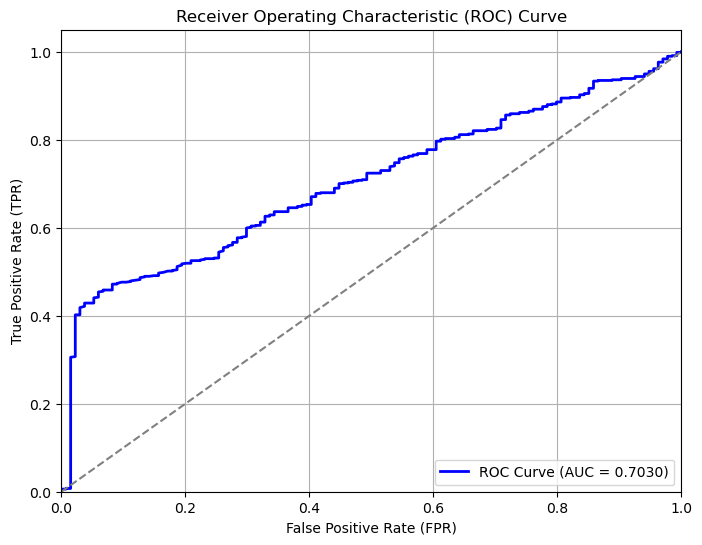

In [8]:
# Vẽ đường cong ROC AUC
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Dự đoán xác suất lớp dương (1)
y_prob = model.predict_proba(X_test)[:, 1]

# Tính FPR, TPR và thresholds cho ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

# Vẽ đồ thị
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Đường baseline
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


# K Nearest Neighbor(KNN)

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import pandas as pd
import numpy as np
import matplotlib.ticker as ticker
from sklearn import preprocessing
%matplotlib inline

ModuleNotFoundError: No module named 'matplotlib'

In [35]:
from sklearn.neighbors import KNeighborsClassifier

In [37]:
k = 6  # trọng số là uniform, coi các điểm đều nhau và có trọng số bằng nhau
#Train Model and Predict  
neigh = KNeighborsClassifier(n_neighbors = k).fit(X_train,y_train)
neigh

KNeighborsClassifier(n_neighbors=6)

In [39]:

from sklearn import metrics
predicted = neigh.predict(X_test)
expected = y_test

y_train_pred = neigh.predict(X_train)

In [41]:
from sklearn import metrics
print("Train set Accuracy: ", metrics.accuracy_score(y_train, neigh.predict(X_train)))
print("Test set Accuracy: ", metrics.accuracy_score(expected, predicted))

Train set Accuracy:  0.901510989010989
Test set Accuracy:  0.8613861386138614


In [43]:
from sklearn.metrics import classification_report
print (classification_report(expected, predicted))

              precision    recall  f1-score   support

           0       0.59      0.52      0.56       134
           1       0.91      0.93      0.92       674

    accuracy                           0.86       808
   macro avg       0.75      0.73      0.74       808
weighted avg       0.86      0.86      0.86       808



In [45]:
from sklearn.metrics import confusion_matrix
confusion_matrix(expected, predicted)

array([[ 70,  64],
       [ 48, 626]], dtype=int64)

In [47]:
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
# Dự đoán xác suất trên tập kiểm tra
y_prob = neigh.predict_proba(X_test)[:, 1]  # Lấy xác suất của lớp dương (1)
# Tính AUC-ROC
auc_roc = roc_auc_score(y_test, y_prob)

# Tính Brier Score
brier = brier_score_loss(y_test, y_prob)

# Tính Log-loss
logloss = log_loss(y_test, y_prob)

# In kết quả
print(f"AUC-ROC: {auc_roc:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"Log-loss: {logloss:.4f}")


AUC-ROC: 0.8472
Brier Score: 0.0988
Log-loss: 0.8234


# Random forest

In [49]:
#Import Random Forest Model
from sklearn.ensemble import RandomForestClassifier

#Create a Gaussian Classifier
clf=RandomForestClassifier(n_estimators=100,max_depth= 5)

#Train the model using the training sets y_pred=clf.predict(X_test)
clf.fit(X_train,y_train)

predicted =clf.predict(X_test)
expected  = y_test


In [51]:
from sklearn import metrics
# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(expected, predicted))

Accuracy: 0.9975247524752475


In [53]:
from sklearn.metrics import classification_report
print (classification_report(expected, predicted))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       134
           1       1.00      1.00      1.00       674

    accuracy                           1.00       808
   macro avg       1.00      0.99      1.00       808
weighted avg       1.00      1.00      1.00       808



In [55]:
from sklearn.metrics import confusion_matrix
confusion_matrix(expected, predicted)

array([[132,   2],
       [  0, 674]], dtype=int64)

In [57]:
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
# Dự đoán xác suất trên tập kiểm tra
y_prob = clf.predict_proba(X_test)[:, 1]  # Lấy xác suất của lớp dương (1)
# Tính AUC-ROC
auc_roc = roc_auc_score(y_test, y_prob)

# Tính Brier Score
brier = brier_score_loss(y_test, y_prob)

# Tính Log-loss
logloss = log_loss(y_test, y_prob)

# In kết quả
print(f"AUC-ROC: {auc_roc:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"Log-loss: {logloss:.4f}")

AUC-ROC: 1.0000
Brier Score: 0.0120
Log-loss: 0.0742


# XGBoost

In [12]:
from numpy import loadtxt
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
model2 = XGBClassifier()
model2.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

In [13]:
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, log_loss
)

# Dự đoán nhãn
y_pred = model2.predict(X_test)

# Dự đoán xác suất cho lớp 1
y_prob = model2.predict_proba(X_test)[:, 1]

# === In kết quả cơ bản ===
print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))

# === Tính toán các chỉ số ===
acc   = accuracy_score(y_test, y_pred)
prec  = precision_score(y_test, y_pred, average='binary')  # dùng 'macro' hoặc 'weighted' nếu đa lớp
rec   = recall_score(y_test, y_pred, average='binary')
f1    = f1_score(y_test, y_pred, average='binary')
auc   = roc_auc_score(y_test, y_prob)
brier = brier_score_loss(y_test, y_prob)
lloss = log_loss(y_test, y_prob)

# === In ra chỉ số đánh giá ===
print("\n=== Evaluation Metrics ===")
print(f"Accuracy     : {acc:.4f}")
print(f"Precision    : {prec:.4f}")
print(f"Recall       : {rec:.4f}")
print(f"F1-score     : {f1:.4f}")
print(f"AUC-ROC      : {auc:.4f}")
print(f"Brier Score  : {brier:.4f}")
print(f"Log-loss     : {lloss:.4f}")

# === Lưu vào dictionary nếu cần ===
results['Accuracy'].append(acc)
results['Precision'].append(prec)
results['Recall'].append(rec)
results['F1-score'].append(f1)

=== Confusion Matrix ===
[[132   2]
 [  0 674]]

=== Classification Report ===
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       134
           1       1.00      1.00      1.00       674

    accuracy                           1.00       808
   macro avg       1.00      0.99      1.00       808
weighted avg       1.00      1.00      1.00       808


=== Evaluation Metrics ===
Accuracy     : 0.9975
Precision    : 0.9970
Recall       : 1.0000
F1-score     : 0.9985
AUC-ROC      : 1.0000
Brier Score  : 0.0015
Log-loss     : 0.0044


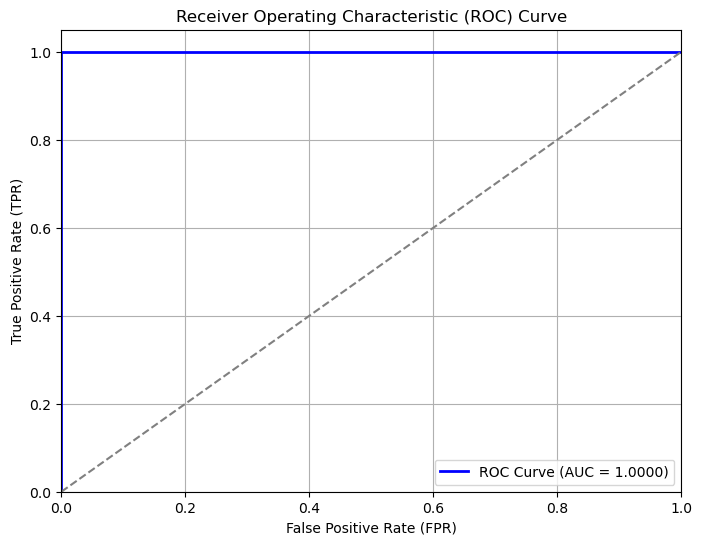

In [16]:
# Vẽ đường cong ROC AUC
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Dự đoán xác suất lớp dương (1)
y_prob = model2.predict_proba(X_test)[:, 1]

# Tính FPR, TPR và thresholds cho ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

# Vẽ đồ thị
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Đường baseline
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


# Tinh chỉnh mô hình

Sau khi đã chạy mô hình cơ bản, có thể cần tinh chỉnh mô hình tốt hơn, một số bước có thể tinh chỉnh như sau.

1. Lựa chọn các siêu tham số để tinh chỉnh \
Các siêu tham số quan trọng trong XGBoost bao gồm: \
Learning rate (eta): Tốc độ học, thường từ 0.01 đến 0.3.\
Max depth: Độ sâu tối đa của cây, thường từ 3 đến 10.\
Min child weight: Trọng số tối thiểu của một node lá, thường từ 1 đến 10.\
Subsample: Tỷ lệ mẫu được sử dụng để huấn luyện mỗi cây, thường từ 0.5 đến 1.0.\
Colsample_bytree: Tỷ lệ đặc trưng được sử dụng cho mỗi cây, thường từ 0.5 đến 1.0. \
N_estimators: Số lượng cây, thường từ 100 đến 1000. \
Gamma: Độ giảm tổn thất tối thiểu để phân chia, thường từ 0 đến 5.\
Regularization (lambda, alpha): Tham số điều chuẩn L2 và L1. \
2. Tinh chỉnh siêu tham số \
Có nhiều phương pháp để tìm bộ siêu tham số tối ưu: \
Grid Search: \
Thử tất cả các tổ hợp siêu tham số trong một lưới được xác định trước. \
Random Search: \
Thử ngẫu nhiên các tổ hợp siêu tham số trong một phạm vi. \
Bayesian Optimization: \
Sử dụng các thư viện như Optuna hoặc BayesianOptimization để tối ưu hóa siêu tham số một cách thông minh. 

3. Sử dụng kỹ thuật Cross-Validation \
Sử dụng k-fold cross-validation (thường k=5 hoặc k=10) để đảm bảo mô hình không bị overfitting và đánh giá hiệu suất ổn định. \
4. Kiểm tra và điều chỉnh thêm\
Phân tích tầm quan trọng đặc trưng: Sử dụng model.feature_importances_ để xác định các đặc trưng quan trọng và loại bỏ các đặc trưng không cần thiết.\
Kiểm tra overfitting:\
So sánh hiệu suất trên tập huấn luyện và tập kiểm tra.\
Nếu mô hình hoạt động tốt trên tập huấn luyện nhưng kém trên tập kiểm tra, tăng gamma, min_child_weight, hoặc giảm max_depth.\
Early Stopping: Dừng huấn luyện nếu hiệu suất trên tập kiểm tra không cải thiện sau một số vòng lặp (early_stopping_rounds). \
    
5. Đánh giá mô hình cuối cùng \
Huấn luyện mô hình với bộ siêu tham số tốt nhất trên toàn bộ tập huấn luyện.\
Đánh giá trên tập thử nghiệm (test set) để có kết quả cuối cùng.\

6. Lưu và triển khai mô hình